# Repeat factor sampling

## 1. Research question and hypothesis

Can class-aware image sampling improve rare-class AP without reducing aggregate mAP? We change Faster R-CNN training-image probabilities using image-level class presence. We keep the number of draws and batch attempts per epoch fixed, without loss weights or clip balancing.

We test one factor against its own detector baseline. Validation AP and Kaggle Public
can disagree: the earlier Faster R-CNN epoch-one candidate had higher local AP but
lower Public score than epoch five. We do not use Public feedback to tune this ablation.

In [1]:
EXPERIMENT = "repeat_factor_sampling"

import json
import logging
import math
import sys
from pathlib import Path
from io import BytesIO

import plotly.express as px
import plotly.io
import polars as pl
import torch
from decouple import config
from IPython.display import Markdown, display
from IPython.display import Image as NotebookImage
from PIL import Image, ImageDraw
from torchvision.transforms.functional import pil_to_tensor, to_pil_image

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s: %(message)s",
    datefmt="%Y-%m-%dT%H:%M:%S",
    stream=sys.stdout,
    force=True,
)
ROOT = Path.cwd() if Path("pyproject.toml").is_file() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

from experiments.protocol import (
    BATCH_ID,
    baseline_directory,
    baseline_protocol_table,
    choose_example_frames,
    class_table,
    epoch_table,
    load_records,
    load_settings,
    loss_table,
    metric_table,
    runtime_table,
    train_experiment,
)
from hm2.detection_data import select_frames
from hm2.faster_rcnn import IgnoreAwareDetectionDataset, ignore_coverage
from hm2.visualization import draw_frame

SHOULD_TRAIN = False
persist_checkpoint = None
METADATA = Path(config("HM2_METADATA_DIR", default=str(ROOT / "data/metadata"))).expanduser()
manifest = METADATA / "manifest.json"
previous_root = json.loads(manifest.read_text()).get("dataset_root") if manifest.exists() else None
DATA_ROOT = Path(config("HM2_DATA_DIR", default=previous_root or str(ROOT / "data"))).expanduser()
OUTPUT = Path(
    config(
        "HM2_DATA_EXPERIMENT_OUTPUT",
        default=str(ROOT / "runs/data_experiments" / BATCH_ID / EXPERIMENT),
    )
).expanduser()
BASELINE = Path(config("HM2_BASELINE_RESULTS", default=str(baseline_directory(ROOT, EXPERIMENT))))
SETTINGS = load_settings(ROOT, EXPERIMENT)
BASELINE_SETTINGS = load_settings(ROOT, EXPERIMENT, is_enabled=False)
plotly.io.renderers.default = "plotly_mimetype"
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(12)


def show_image(image: Image.Image) -> None:
    image.thumbnail((1000, 450))
    buffer = BytesIO()
    image.convert("RGB").save(buffer, format="JPEG", quality=40, optimize=True)
    display(NotebookImage(data=buffer.getvalue(), format="jpeg"))


{
    "Experiment": EXPERIMENT,
    "Training enabled": SHOULD_TRAIN,
    "Output": str(OUTPUT),
    "Baseline records": str(BASELINE),
    "Exact configuration": SETTINGS,
}

{'Experiment': 'repeat_factor_sampling',
 'Training enabled': False,
 'Output': '/Users/nikitalenyk/Desktop/hm2/runs/data_experiments/controlled_data_stride5_5epochs_seed2026/repeat_factor_sampling',
 'Baseline records': '/Users/nikitalenyk/Desktop/hm2/runs/faster_rcnn/faster_rcnn_stride5_5epochs_seed2026/baseline_stride5',
 'Exact configuration': {'dataset': {'frame_stride': 5,
   'expected_selected_frames': 4868,
   'expected_selected_clips': 56,
   'expected_validation_frames': 2846,
   'should_stage_images': True},
  'model': {'min_size': 640,
   'max_size': 1024,
   'detections_per_img': 500,
   'is_ignore_aware': True,
   'ignore_threshold': 0.5},
  'training': {'seed': 2026,
   'epochs': 5,
   'batch_size': 2,
   'num_workers': 2,
   'learning_rate': 0.0025,
   'warmup_updates': 100,
   'flip_probability': 0.5,
   'checkpoint_seconds': 600},
  'evaluation': {'batch_size': 2, 'num_workers': 2},
  'sampling': {'threshold': 0.5, 'max_repeat': 4.0},
  'data_experiment': {'name': 're

## 2. Baseline and experimental configuration

We use seed 2026, 4,868 stride-five training frames from 56 clips, full official validation
on 2,846 frames from seven separate clips, batch size 2 and five epochs. SGD uses LR 0.0025,
momentum 0.9 and weight decay 0.0001, with the baseline warmup and two LR reductions.
Initialization uses the original COCO-pretrained detector, never a fine-tuned baseline.
We retain each baseline's anchors, loss, pretrained normalization and inference limits.
The configuration displayed above is loaded from the corresponding TOML file.
The protocol comparison below checks restored original baseline records.

In [2]:
has_metadata = all(
    (METADATA / f"{name}.parquet").is_file() for name in ("frames", "objects", "ignored_regions")
)
selected = validation = frames = objects = ignored = pl.DataFrame()
if has_metadata:
    frames, objects, ignored = (
        pl.read_parquet(METADATA / f"{name}.parquet")
        for name in ("frames", "objects", "ignored_regions")
    )
    selected = select_frames(frames, "train", 5)
    validation = select_frames(frames, "val")
    display(
        pl.DataFrame(
            {
                "Split": ["Training stride 5", "Official validation"],
                "Frames": [selected.height, validation.height],
                "Clips": [selected["clip"].n_unique(), validation["clip"].n_unique()],
            }
        )
    )
else:
    display(
        Markdown(
            "**Data not restored.** Run `00_data.ipynb` or restore the original parquet metadata. No download is started."
        )
    )

has_images = (
    has_metadata and DATA_ROOT.is_dir() and (DATA_ROOT / selected["relative_path"][0]).is_file()
)

Split,Frames,Clips
str,i64,i64
"""Training stride 5""",4868,56
"""Official validation""",2846,7


## 3. Dataset diagnostics and visual examples

We use $f_c = N_c/N$ and $r_c=\max(1,\sqrt{t/f_c})$, then assign each image its
largest present-class factor, capped at 4. The initial threshold 0.01 is a no-op on this
selection: even bus occurs in about 27% of images. We preselect threshold 0.5 from training
class presence only. This is a fixed-budget weighted form of RFS: normalized image factors
define replacement probabilities, and each epoch still draws exactly 4,868 frames.
It does not expand epochs. Unit factors reproduce the baseline permutation exactly.
The nominal budget is 12,170 batch attempts; actual successful AMP updates are recorded
and can be slightly lower. We inspect rare-class clip concentration and adjacent frames
because repeating the same objects need not add scene diversity.

category_id,class_name,image_count,clip_count,max_clip_share,frame_frequency
i64,str,u32,u32,f64,f64
1,"""person""",4420,55,0.063348,0.90797
2,"""bicycle""",2562,41,0.101483,0.526294
3,"""car""",4230,49,0.067376,0.86894
4,"""van""",3037,46,0.061574,0.62387
5,"""truck""",2314,39,0.075627,0.475349
6,"""tricycle""",2623,39,0.092261,0.538825
7,"""bus""",1333,24,0.108777,0.273829
8,"""motor""",3439,50,0.068043,0.70645


Threshold,Maximum image factor,Draws per epoch,Nominal five-epoch updates,Unique frames in sampled epoch
f64,f64,i64,i64,i64
0.01,1.0,4868,12170,4868
0.5,1.35128,4868,12170,3037


category_id,class_name,image_count,clip_count,max_clip_share,frame_frequency,expected_draws,actual_draws
i64,str,u32,u32,f64,f64,f64,u32
1,"""person""",4420,55,0.063348,0.90797,4388.058384,4418
2,"""bicycle""",2562,41,0.101483,0.526294,2580.23933,2618
3,"""car""",4230,49,0.067376,0.86894,4283.779629,4275
4,"""van""",3037,46,0.061574,0.62387,3113.347083,3089
5,"""truck""",2314,39,0.075627,0.475349,2414.457253,2335
6,"""tricycle""",2623,39,0.092261,0.538825,2622.674001,2619
7,"""bus""",1333,24,0.108777,0.273829,1632.084765,1577
8,"""motor""",3439,50,0.068043,0.70645,3464.350065,3451


clip,Frames,First frame,Last frame
str,u32,i64,i64
"""uav0000244_01440_v""",145,1,721
"""uav0000248_00001_v""",136,1,676
"""uav0000263_03289_v""",128,1,721
"""uav0000222_03150_v""",85,1,421
"""uav0000126_00001_v""",83,1,411
"""uav0000300_00000_v""",82,1,406
"""uav0000326_01035_v""",56,1,276
"""uav0000273_00001_v""",53,126,801


**Temporal concentration check.** Adjacent selected frames from the most represented rare-class clip; shared objects are not independent examples.

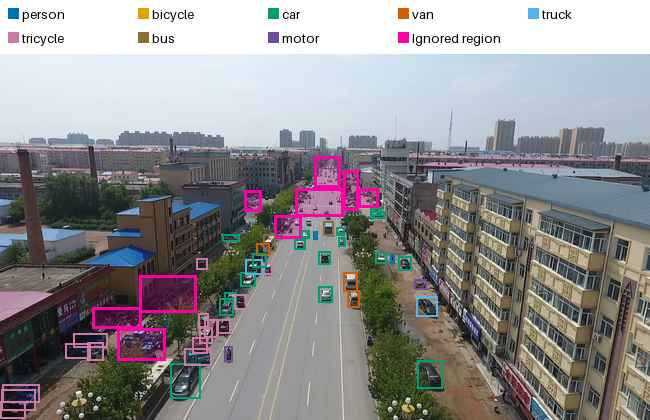

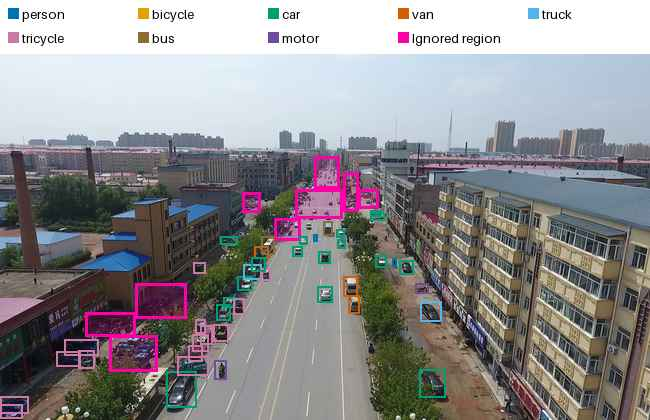

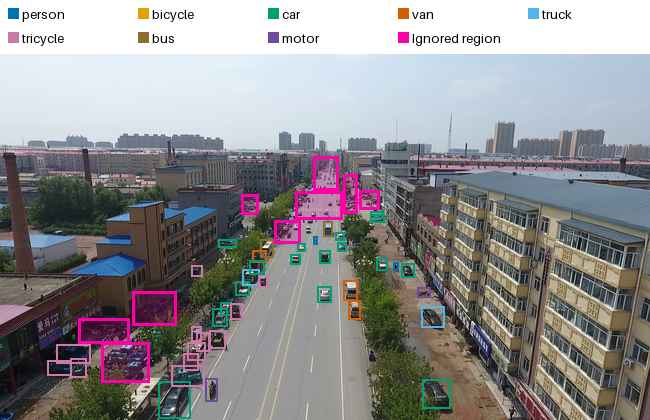

From frame,To frame,Frame gap,Mean absolute RGB difference
i64,i64,i64,f64
1,6,5,0.029097
6,11,5,0.02835


Pixel differences use 64 × 36 RGB previews on [0, 1]. They describe adjacent-frame appearance, not independent scene diversity.

In [3]:
from experiments.repeat_factor_sampling import (
    class_presence_statistics,
    image_repeat_factors,
    sample_epoch_indices,
    sampling_exposure,
)

if has_metadata:
    presence = class_presence_statistics(selected, objects)
    initial = image_repeat_factors(selected, objects, threshold=0.01)
    factors = image_repeat_factors(selected, objects, **SETTINGS["sampling"])
    indices = sample_epoch_indices(factors["repeat_factor"].to_list(), 2026, 0)
    exposure = sampling_exposure(selected, objects, factors, indices)
    display(presence)
    display(
        pl.DataFrame(
            {
                "Threshold": [0.01, SETTINGS["sampling"]["threshold"]],
                "Maximum image factor": [
                    initial["repeat_factor"].max(),
                    factors["repeat_factor"].max(),
                ],
                "Draws per epoch": [selected.height, len(indices)],
                "Nominal five-epoch updates": [math.ceil(selected.height / 2) * 5] * 2,
                "Unique frames in sampled epoch": [selected.height, len(set(indices))],
            }
        )
    )
    display(exposure)
    chart = exposure.select("class_name", "image_count", "expected_draws", "actual_draws").unpivot(
        index="class_name", variable_name="Exposure", value_name="Frames"
    )
    chart = chart.with_columns(
        pl.col("Exposure").replace_strict(
            {
                "image_count": "Baseline",
                "expected_draws": "Expected RFS",
                "actual_draws": "Sampled RFS",
            }
        )
    )
    display(
        px.bar(
            chart,
            x="class_name",
            y="Frames",
            color="Exposure",
            barmode="group",
            labels={"class_name": "Class"},
            title="Class-bearing image exposure per epoch",
        ).update_layout(width=1000, height=450, legend=dict(orientation="h", y=-0.25))
    )
    rare_category = presence.filter(pl.col("image_count") > 0).sort("frame_frequency")[
        "category_id"
    ][0]
    rare_keys = objects.filter(pl.col("category_id") == rare_category).select("image_key").unique()
    rare_frames = selected.join(rare_keys, on="image_key", how="semi")
    clip_coverage = (
        rare_frames.group_by("clip")
        .agg(
            pl.len().alias("Frames"),
            pl.col("frame_id").min().alias("First frame"),
            pl.col("frame_id").max().alias("Last frame"),
        )
        .sort("Frames", descending=True)
    )
    display(clip_coverage.head(8))
    if has_images and not rare_frames.is_empty():
        top_clip = clip_coverage["clip"][0]
        neighbors = rare_frames.filter(pl.col("clip") == top_clip).sort("frame_id").head(3)
        display(
            Markdown(
                "**Temporal concentration check.** Adjacent selected frames from the most represented rare-class clip; shared objects are not independent examples."
            )
        )
        for record in neighbors.iter_rows(named=True):
            show_image(
                draw_frame(
                    DATA_ROOT / record["relative_path"],
                    objects.filter(pl.col("image_key") == record["image_key"]),
                    ignored.filter(pl.col("image_key") == record["image_key"]),
                    max_width=650,
                    should_label=False,
                )
            )
        appearances = []
        previous = None
        for record in neighbors.iter_rows(named=True):
            with Image.open(DATA_ROOT / record["relative_path"]) as source:
                pixels = pil_to_tensor(source.convert("RGB").resize((64, 36))).float() / 255
            if previous is not None:
                appearances.append(
                    {
                        "From frame": previous[0],
                        "To frame": record["frame_id"],
                        "Frame gap": record["frame_id"] - previous[0],
                        "Mean absolute RGB difference": float((pixels - previous[1]).abs().mean()),
                    }
                )
            previous = (record["frame_id"], pixels)
        display(pl.from_dicts(appearances))
        display(
            Markdown(
                "Pixel differences use 64 × 36 RGB previews on [0, 1]. They describe adjacent-frame appearance, not independent scene diversity."
            )
        )

## 4. Experiment execution

We use `experiments/03_data_experiments_kaggle.ipynb` to train this experiment and save
resumable checkpoints to Drive. Set its `EXPERIMENT` to the name shown above.
This research notebook loads saved records; training here remains disabled by default.

In [4]:
if SHOULD_TRAIN:
    if persist_checkpoint is None:
        raise RuntimeError(
            "Configure the verified Drive callback using the execution notebook first."
        )
    if not has_images:
        raise ValueError("Restore local images and metadata before training.")
    display(
        train_experiment(
            EXPERIMENT, DATA_ROOT, METADATA, OUTPUT, SETTINGS, on_checkpoint=persist_checkpoint
        )
    )
else:
    display(
        Markdown(
            "**Training disabled.** Use the dedicated execution notebook when GPU execution is authorized."
        )
    )

**Training disabled.** Use the dedicated execution notebook when GPU execution is authorized.

## 5. Training and validation results

We load measured records on every run. Missing results remain Not run, and unfinished
training remains Partial. Final-epoch metrics are the controlled comparison; best-validation
metrics are shown separately. New ablations retain best.pt, while the historical Faster
R-CNN baseline retained only latest.pt. A best metric in its history does not imply its
old checkpoint is still available. Timings exclude setup and checkpoint transfer.

In [5]:
variant = load_records(OUTPUT)
baseline = load_records(BASELINE)
records = {"Baseline": baseline, "Data variant": variant}
display(metric_table(records))
display(runtime_table(records))
display(baseline_protocol_table(baseline, BASELINE_SETTINGS))
if variant["config"]:
    display(variant["config"])
if variant["status"] == "Not run":
    display(
        Markdown(
            "**Not run.** No trained-variant validation metrics exist yet. Baseline values do not establish an improvement."
        )
    )
if has_images and baseline["config"].get("dataset_selection_sha256"):
    from hm2.faster_rcnn_experiments import compute_source_identity

    keys = selected["image_key"].to_list()
    actual_identity = compute_source_identity(DATA_ROOT, keys)
    display(
        pl.DataFrame(
            {
                "Exact baseline dataset/selection hash matches": [
                    actual_identity == baseline["config"]["dataset_selection_sha256"]
                ]
            }
        )
    )

Run,Status,Selection,Epoch,mAP,AP50,AP75,AP small,AP medium,AP large,Training min,Validation ms/frame
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""Baseline""","""Completed""","""Final epoch""",5,0.174703,0.353521,0.152856,0.080675,0.168725,0.334301,75.631758,89.321728
"""Baseline""","""Completed""","""Best validation epoch""",1,0.192021,0.398392,0.161919,0.089808,0.177219,0.354186,15.262009,92.792669
"""Data variant""","""Not run""","""Final epoch""",null,null,null,null,null,null,null,null,null
"""Data variant""","""Not run""","""Best validation epoch""",null,null,null,null,null,null,null,null,null


Run,Status,Training min,Validation min,Images/s,Peak allocated MiB,Minimum free MiB,GPU
str,str,f64,f64,f64,null,null,str
"""Baseline""","""Completed""",75.631758,34.744474,5.363708,null,null,"""Tesla T4"""
"""Data variant""","""Not run""",null,null,null,null,null,null


Setting,Expected,Recorded,Matches
str,str,str,bool
"""seed""","""2026""","""2026""",true
"""epochs""","""5""","""5""",true
"""batch_size""","""2""","""2""",true
"""learning_rate""","""0.0025""","""0.0025""",true
"""warmup_updates""","""100""","""100""",true
"""flip_probability""","""0.5""","""0.5""",true
"""frame_stride""","""5""","""5""",true
"""min_size""","""640""","""640""",true
"""max_size""","""1024""","""1024""",true


**Not run.** No trained-variant validation metrics exist yet. Baseline values do not establish an improvement.

Exact baseline dataset/selection hash matches
bool
true


## 6. Baseline comparison

We use canonical COCO bbox AP at IoU 0.50:0.95, maxDets [1, 10, 100], and the original
category-specific COCO crowd annotations. Faster R-CNN also records maxDets 500.
The original validation set is unchanged. Metrics are not the competition custom score.
We show each metric on a separate chart to keep axes and legends readable.

In [6]:
epochs = epoch_table(records)
if not epochs.is_empty():
    for metric in ("mAP", "AP50", "AP75", "AP small", "AP medium", "AP large"):
        display(
            px.line(
                epochs.filter(pl.col("Metric") == metric),
                x="Epoch",
                y="AP",
                color="Run",
                markers=True,
                title=f"Validation {metric}",
            ).update_layout(width=1000, height=420, legend=dict(orientation="h", y=-0.25))
        )
classes = class_table(records)
if not classes.is_empty():
    display(classes.pivot(on="Run", index=["Class", "Epoch"], values="AP"))
    display(
        px.bar(
            classes,
            x="Class",
            y="AP",
            color="Run",
            barmode="group",
            title="Per-class AP at the last completed validation",
        ).update_layout(width=1000, height=450, legend=dict(orientation="h", y=-0.25))
    )
for label, record in records.items():
    curve = loss_table(record)
    if not curve.is_empty():
        display(
            px.line(curve, x="Updates", y="Loss", title=f"{label}: training loss").update_layout(
                width=1000, height=420
            )
        )
        display(
            px.line(
                curve, x="Updates", y="Learning rate", title=f"{label}: learning-rate schedule"
            ).update_layout(width=1000, height=380)
        )

Class,Epoch,Baseline
str,i64,f64
"""person""",5,0.247199
"""bicycle""",5,0.14803
"""car""",5,0.356788
"""van""",5,0.236865
"""truck""",5,0.139097
"""tricycle""",5,0.16438
"""bus""",5,0.014804
"""motor""",5,0.090464


## 7. Interpretation and limitations

No data-variant training result exists until this experiment is run. We will assess
final-epoch mAP together with AP75, object sizes, per-class AP, throughput and memory.
An isolated rare-class improvement does not establish overall success. A single seed
and only seven validation videos limit generalization claims; GPU runtime changes and
AMP update skips can affect reproducibility. Historical GPU memory was not recorded
for every baseline and is shown as missing rather than inferred.

We restore original JSON records from Drive only when needed. Use `HM2_BASELINE_RESULTS`
and `HM2_DATA_EXPERIMENT_OUTPUT` to point to restored records. Run the repository from
its root with `uv run jupyter lab notebooks/`. GPU execution uses
`experiments/03_data_experiments_kaggle.ipynb`; setup instructions are in
[the experiment README](../experiments/README.md).

Implementation reference: [Detectron2 repeat-factor sampler](https://github.com/facebookresearch/detectron2/blob/main/detectron2/data/samplers/distributed_sampler.py).